# Session 9b · How LLMs work
## What the model actually sees: tokens, cost, the context window, embeddings

**How to use this notebook.** It has three parts.

| Part | What it is | Code? |
|---|---|---|
| **Part A · Read before you run** | Why this topic matters, the words you need, and how today's session is built | No code. Read it first (about 15 minutes). |
| **Part B · Hands-on** | Sections 1 to 7. Every section follows the same six steps (below). | Yes |
| **Part C · Wrap-up** | Summary, interview questions, troubleshooting | No |

Every section in Part B follows the same six steps, so you always know where you are:

1. **What and why** — what we are about to do and why it matters.
2. **The idea** — the concept, with an analogy and often a small diagram.
3. **What the next cell does** — a numbered walk-through *before* you see the code.
4. **The code** — run it.
5. **What you should see** — how to read the output, and what it means if yours is different.
6. **Check yourself** — one short question and a common mistake to avoid.

Boxes marked **▸ Read more** are optional. Click to open them when you want the deeper background; you can skip them in class.

**Before you start:** in PowerShell, inside the course folder, run `git pull` and then `uv sync`. Open this notebook with `uv run jupyter lab`, or in VS Code with the project's `.venv` kernel selected. Run every cell from top to bottom (**Kernel → Restart & Run All** works too).

---
# Part A · Read before you run

## A1. Why this session matters

### The problem, in one story
*An imagined but typical case.* A bank launches a WhatsApp assistant for loan questions, in English and Telugu. The cost plan was made by counting **words** in English sample messages. In the first month, three things go wrong:

1. **The bill is bigger than planned.** The model reads *tokens*, not words, and the same loan question in Telugu needs more of them (25 against 16 on today's tokenizer). The answers are long too, and providers charge *more* for tokens the model writes than for tokens it reads.
2. **The assistant "forgets".** A customer pastes a three-page loan statement and chats for half an hour. Near the end, the assistant asks again for the loan type she gave at the start. The conversation no longer fit into the model's **context window**, and the oldest part was dropped. Nobody had decided *what* to drop.
3. **The FAQ search misses obvious answers.** The customer writes *"my EMI bounced"*; the FAQ page is titled *"Loan instalment payment failed"*. No shared words, so keyword search finds nothing. The meaning is the same, and **embeddings** can see that.

None of these is a "bad model" problem. **They come from not knowing what the model actually sees.** That is today's topic.

### What you learn today, and what each one prevents

| You learn to... | It prevents... | Everyday name |
|---|---|---|
| Count **tokens** before you send, and read the **usage** field after | Budgets based on words, and surprise bills | Count the bricks, not the words |
| Turn token counts into a **cost** per call and per 1,000 calls | Choosing a model without knowing what it costs at scale | The price card |
| Treat the **context window** as a budget that grows every turn | An assistant that silently forgets the start of a conversation | The desk that fills up |
| Use an **embedding model** to turn text into a vector | Search that only matches exact words | Meaning as coordinates |

### Where this is used in industry
- **Banking (BFS):** before a chatbot or document-summary feature goes live, teams forecast tokens per request × requests per day, then track the real `usage` numbers (Session 53).
- **Multilingual service (banking, telecom, public services in India):** other scripts usually cost more tokens per message, so cost and context limits are planned per language.
- **Healthcare:** long clinical notes may not fit comfortably in a prompt, so teams decide what to keep, summarise or retrieve (Sessions 19, 30, 38).
- **Insurance and retail:** semantic search over policies, catalogues and past tickets runs on embeddings, so "my car was rear-ended" finds the collision clause (Session 24, Module 5).

### Why interviewers care
These questions come up in AI-engineer and GenAI-developer interviews:
- *"What is a token, and why don't models just use words?"*
- *"Why can the provider's token count differ from the one you calculated?"*
- *"How would you estimate the monthly cost of an LLM feature?"*
- *"What is a context window, and what happens when a conversation is longer than it?"*
- *"What is an embedding, and what is it used for?"*

By the end of today you can answer each one with a definition, an example from your own lab, and one honest limit. Part C has model answers.

## A2. Where this session fits in the course

```
 S9a  Environment and your first LLM call ─► uv, .env, hello.py; it printed "prompt=96 completion=105 total=201"
  │ S9b  How LLMs work ───────────────────────► TODAY: tokens, usage, cost, the context window, embeddings
  │
 S10  The model landscape ─────────────────► choose a model on cost, context length, latency, residency:
  │                                          today's cost and context numbers are the inputs
 S11  Multi-provider API calls ────────────► the same client for several providers; temperature, max_tokens,
  │                                          streaming, and reading usage on every call
 S12  Local and open models ───────────────► Ollama on your laptop: the llama3.2:3b we compare against today
 S13  Multimodal and structured output ────► images in, JSON out; images cost tokens too
  ·
 S19  Chat application architecture ───────► the context budget for real: sliding window and summaries
 S24  Embeddings ──────────────────────────► today's meaning map becomes a working semantic search
 S38  Memory and context engineering ──────► keeping an agent's context under a budget
```

**What you need from earlier sessions:**
- The course repository cloned, with `git pull` and `uv sync` done today (new packages for this session: `jupyter`, `tiktoken`, `numpy`, `matplotlib`).
- A working `.env` with your Groq key, from Session 9a (`uv run pytest tests/test_setup.py` was green). Without a key the notebook still runs; section 3 says "skipped".
- Optional: Ollama with `llama3.2:3b` (Session 9a pre-work) and `nomic-embed-text` (`ollama pull nomic-embed-text`). Without them, section 3 shows `(no ollama)` and section 6 uses a cached file if your repository has one.
- Internet once: the first time `tiktoken` counts tokens, it downloads its dictionary file and keeps it on your laptop.

## A3. The words you need today

Read these once now. Each term appears in **bold** the first time it is used in Part B.

---
**1. Provider and model**
- **Definition:** the **provider** is *where* the model runs (Groq in the cloud, Ollama on your laptop), set by `BASE_URL`. The **model** is *which brain* answers, set by `MODEL`.
- **Analogy:** a provider is a hospital; a model is the doctor you see there.
- **Example:** `openai/gpt-oss-20b` on Groq; `llama3.2:3b` on Ollama.
- **Often confused with:** the client library: `openai` is the phone you dial with, and it can call many providers.
- **Comes back in:** S10, S11, S12, Module 12.

---
**2. Token**
- **Definition:** the unit a model reads and writes: a piece of text from a fixed dictionary. In English, about three quarters of a word on average.
- **Analogy:** a Lego brick. Common words are one big brick; rare words are built from several small ones.
- **Example:** the loan question is 16 tokens; *rupees* is two: `' ru'` and `'pees'`.
- **Often confused with:** a word or a character. A token can be a word, part of a word, a space, a group of digits, or punctuation.
- **Comes back in:** every cost line from now on; S19, S34, S38.

---
**3. Tokenizer and encoding**
- **Definition:** the **tokenizer** cuts text into tokens and turns them into numbers (token IDs); it belongs to the model. An **encoding** names one dictionary (gpt-oss uses `o200k_harmony`). **`tiktoken`** is OpenAI's open-source library that counts with these encodings on your laptop.
- **Analogy:** the Lego set (which bricks exist), and the name printed on its box.
- **Example:** the same Telugu sentence gives one count on gpt-oss's tokenizer and another on Llama's.
- **Often confused with:** the model itself. For a model with another tokenizer, a `tiktoken` count is only an estimate.
- **Comes back in:** S19, S38.

---
**4. The `usage` field**
- **Definition:** returned with every answer: `prompt_tokens` (read), `completion_tokens` (written), `total_tokens`.
- **Analogy:** the itemised bill after the meal, not your guess from the menu.
- **Example:** `hello.py` printed `prompt=96 completion=105 total=201`.
- **Often confused with:** your `tiktoken` count: an estimate *before* you send. `usage` is the truth *after*.
- **Comes back in:** every lab; S53, S54.

---
**5. Chat template (the wrapper)**
- **Definition:** extra tokens the provider wraps round your messages (role markers, sometimes a default system message). Counted in `prompt_tokens`.
- **Analogy:** the envelope round your letter: postage is charged on both.
- **Example:** you type 16 tokens; `usage.prompt_tokens` comes back larger.
- **Comes back in:** S19, S38, S53.

---
**6. Input and output price**
- **Definition:** a price per million tokens, separately for input and output; output costs more.
- **Analogy:** a taxi whose ride meter runs faster than its booking fee.
- **Example:** the course's first price card: 0.075 US dollars in, 0.30 out, per million tokens.
- **Comes back in:** S10, S53, S54.

---
**7. Context window**
- **Definition:** the most tokens a model can see at once: system prompt, history, documents, tool results, and the answer.
- **Analogy:** a desk of fixed size, re-read in full every turn.
- **Example:** our simulated chat holds 1,550 tokens after 20 turns.
- **Often confused with:** memory. The model keeps nothing between calls; your code re-sends the history every time.
- **Comes back in:** S19, S30, S34, S38.

---
**8. Next-token prediction**
- **Definition:** how answers are made: score every possible next token, pick one, add it, repeat.
- **Analogy:** your phone's next-word suggestion, looking at the whole conversation.
- **Example:** after *"a loan of 8 lakh at 11.5% for"*, likely next tokens include `' five'` and `' 5'`.
- **Often confused with:** looking up a stored answer: generated text can be fluent and wrong.
- **Comes back in:** S11 (temperature), S15 (reasoning models).

---
**9. Attention**
- **Definition:** how a model weighs which earlier tokens matter most for the next one (intuition only).
- **Analogy:** underlining the important words before you answer.
- **Example:** for the EMI sentence, *8 lakh* and *11.5%* matter more than *the* or *on*.
- **Often confused with:** the context window (how much it sees, not how it weighs it).
- **Comes back in:** intuition only.

---
**10. Embedding (vector)**
- **Definition:** a list of numbers (a **vector**) standing for a text's meaning; similar meanings point in similar directions.
- **Analogy:** coordinates on a city map: Hitech City and Gachibowli are close, Charminar further away.
- **Example:** `nomic-embed-text` turns *loan* into 768 numbers.
- **Often confused with:** a token ID: one whole number naming a dictionary piece.
- **Comes back in:** S24, Modules 4 and 5, S39.

---
**11. Embedding model**
- **Definition:** a model whose output is a vector, not text. It never answers.
- **Analogy:** a surveyor who gives coordinates, not advice.
- **Example:** `nomic-embed-text` on Ollama. Groq, our chat provider, offers no embedding models.
- **Often confused with:** a chat model. Also: vectors from different embedding models cannot be compared.
- **Comes back in:** S24, Module 5.

---
**12. PCA**
- **Definition:** Principal Component Analysis: flattens many dimensions to a few (768 to 2), keeping the directions of biggest difference.
- **Analogy:** flattening a globe into a paper map: easy to look at, but distances bend.
- **Example:** today's plot of ten words.
- **Often confused with:** the search itself: real search uses all 768 numbers.
- **Comes back in:** S24.

---
**13. Pre-training, fine-tuning, preference tuning**
- **Definition:** **pre-training**: predict the next token over a huge corpus (a *base model*). **Fine-tuning** (instruction tuning): train on instruction-and-answer pairs (a *chat model*). **Preference tuning** (RLHF and similar): nudge towards answers people preferred.
- **Analogy:** a student reads a library, is coached for exams, then gets feedback from teachers.
- **Example:** the models you call today are chat models: all three stages are done.
- **Often confused with:** your prompt. Training changes the model's weights; a prompt changes nothing permanent.
- **Comes back in:** S10, S12, S15, S54, S57.

---
**14. Knowledge cutoff**
- **Definition:** the date after which the model saw no training data. Anything later must be in the context.
- **Analogy:** the library closed on a certain date.
- **Example:** the model cannot know a rate the bank changed last week unless your prompt tells it.
- **Comes back in:** S10, Module 5.

## A4. How this session is built

### The big picture

```
┌──── COURSE REPOSITORY (you pull it; you do not edit it) ───────────────────────────────────────────────────┐
│                                                                                                            │
│ module01/tokens_utils.py   THE TOOLS this notebook calls                                                   │
│    tokenizer : count_tokens · show_tokens            (ENCODING = "o200k_harmony", via tiktoken)            │
│    cost      : PRICE_CARDS (3 indicative cards, USD per 1M tokens) · USD_TO_INR = 84 · cost_inr            │
│    clients   : chat_client (your .env provider) · ollama_client (localhost:11434) · usage_for              │
│    embeddings: WORDS (10 words) · load_points → embed_via_ollama or the cache file → pca_2d                │
│                                                                                                            │
│ module01/embeddings_10words.json   fallback vectors for section 6 (made by the instructor; may be absent)  │
│ module01/reading_tokens.md · terms_s09.md   the pre-read and the word list                                 │
│                                                                                                            │
│ module01/s09_tokens.ipynb  ◄── YOU ARE HERE                                                                │
│ tests/test_s09.py           the checkpoint (pytest, 4 tests)                                               │
└────────────────────────────────────────────────────────────────────────────────────────────────────────────┘
                         │ the notebook reads your settings and talks to ▼
┌──── YOUR MACHINE (yours; never committed) ─────────────────────────────────────────────────────────────────┐
│ .env                 BASE_URL · API_KEY · MODEL   (read with load_dotenv(override=True))                   │
│ tiktoken's cache     the o200k dictionary file, downloaded once on first use, then offline                 │
│ Ollama (optional)    llama3.2:3b (chat) · nomic-embed-text (embeddings) · http://localhost:11434           │
└────────────────────────────────────────────────────────────────────────────────────────────────────────────┘
                         │ only section 3 leaves your laptop ▼
                 Groq API (cloud)  ·  openai/gpt-oss-20b  ·  returns the usage numbers
```

Today there are **no files to write** into your work repository: you produce five reflection answers (section 7) and a green checkpoint.

### What happens to one sentence

```
 "Can I get a personal loan of 8 lakh rupees for five years?"
        │
        ├──► tokenizer (tiktoken, o200k_harmony) ─► 16 pieces ─► count_tokens = 16      [section 2]
        │                                                        show_tokens = the pieces
        │
        ├──► messages list ─► provider adds its chat template ─► the model reads it all
        │                                                        │
        │                                       usage.prompt_tokens = 16 + the wrapper   [section 3]
        │
        ├──► tokens in × input price + tokens out × output price ─► ₹ per call, ₹ per 1,000 calls  [section 4]
        │
        ├──► appended to the conversation, turn after turn ─► total tokens on the "desk"  [section 5]
        │                                                     vs the context limit
        │
        └──► an embedding model (nomic-embed-text) ─► 768 numbers ─► PCA ─► one dot on a 2-D map  [section 6]
             (here we embed ten single words, not this sentence)
```

### The helpers you will call, and what each does

| Helper | Lives in | You give it | It gives back | Used in section |
|---|---|---|---|---|
| `chat_client()` | tokens_utils | nothing (reads `.env`) | a client for your provider (Groq) | 1 |
| `ollama_client()` | tokens_utils | nothing | a client for Ollama on your laptop | 1, 3 |
| `count_tokens(text)` | tokens_utils | a text | the number of tokens | 1–5 |
| `show_tokens(text)` | tokens_utils | a text | the list of pieces the model sees | 2 |
| `usage_for(client, model, text)` | tokens_utils | a client, a model, a text | `(prompt_tokens, completion_tokens)` from the model | 3 |
| `PRICE_CARDS` | tokens_utils | — (a dict) | three indicative cards, USD per million tokens | 4 |
| `cost_inr(p_in, p_out, card, calls=1)` | tokens_utils | tokens in and out, a card, calls | the cost in rupees (4 decimals) | 4 |
| `WORDS` | tokens_utils | — (a list) | the ten words to embed | 6 |
| `load_points(words)` | tokens_utils | a list of words | `(points, source)`: 2-D points, and where the vectors came from | 6 |
| `pca_2d(vectors)` | tokens_utils | an N × D array | an N × 2 array (inside `load_points`) | 6 |

You do not need to read `tokens_utils.py`: three **under the hood** cells rebuild the key helpers in front of you and check them against the real ones.

### The order of the sections

| # | Section | Calls a model? | Minutes |
|---|---|---|---|
| 1 | Setup — two providers, one client library | no | 3 |
| 2 | What a token is (+ under the hood) | no | 8 |
| 3 | Check against reality — the `usage` field | yes: 4 calls to Groq, and 4 to Ollama if it is running | 6 |
| 4 | What it costs (+ under the hood) | no | 6 |
| 5 | The context window as a budget | no | 6 |
| 6 | Embeddings — meaning as coordinates (+ under the hood) | 1 call to Ollama for 10 words, if it is running | 7 |
| 7 | Reflection | no | 5 |

## A5. What you will be able to do, and what you will submit

**By the end of this session you will be able to:**
1. **Explain** what a token is, and why the same meaning costs different numbers of tokens in different languages and formats.
2. **Count** the tokens of a text before sending it, and **compare** your count with the `usage` field the model returns.
3. **Calculate** the cost of a call, and of 1,000 calls, from token counts and a price card, and say why output tokens matter more.
4. **Describe** the context window as a budget, and **predict** when a growing conversation will run out of room.
5. **Explain** what an embedding is, read a 2-D picture of embeddings, and say what an embedding model cannot do.
6. **Distinguish** pre-training, fine-tuning and preference tuning in one sentence each (from the lecture; terms 13 and 14).

**What you submit:**

| Where | What it must contain |
|---|---|
| Section 7 of this notebook | Your answers to Questions 1 to 5, one or two lines each |
| The checkpoint | `uv run pytest tests/test_s09.py -rs` in PowerShell, in the course folder |

**About the checkpoint.** `tests/test_s09.py` has four tests: two need only the tokenizer, one needs your key, one needs Ollama with `nomic-embed-text` or the cached file. `-rs` prints the reason for every skip. *A skipped test is not a pass*: fix what the reason names, or tell the instructor.

**Budget:** tiny. Section 3 makes four short Groq calls (each writes at most 16 tokens); everything else runs on your laptop.

---
# Part B · Hands-on

## 1. Setup — two providers, one client library

### What and why
The notebook finds today's helper file, reads your `.env`, and makes two clients: Groq (cloud) and Ollama (laptop). It also checks two things that are often missing on a student laptop: **your key** and **the tokenizer's dictionary file**. If one is missing, it says so now, and the sections that need it print "skipped" instead of crashing.

A **provider** is *where* the model runs; a **model** is *which brain* answers. The same client library talks to both — only `base_url` changes. We use Groq (from `.env`) for chat and Ollama (on your laptop) for embeddings.

### The idea: a provider is just an address
```
                     ┌─► chat_client()   base_url = BASE_URL from .env  ─► Groq (cloud)     openai/gpt-oss-20b
  one library:  ─────┤
  openai.OpenAI      └─► ollama_client() base_url = http://localhost:11434/v1 ─► Ollama (laptop) llama3.2:3b,
                                                                                                nomic-embed-text
```
The `openai` library is a phone; Groq and Ollama are two numbers you can dial. That is why you switch provider by editing `.env`, never the code (Session 11).

### What the next cell does
1. **`sys.path[:0] = [...]`** puts three folders at the *front* of Python's search list (`[:0]` is a *slice* meaning "before the first item"), so `import tokens_utils` works from the course folder or from `module01/`.
2. **`from tokens_utils import *`** imports every public name in the helper file (the A4 table). Importing it also runs `load_dotenv(override=True)`, so `.env` is read *before* any check.
3. **`os.getenv("MODEL")`** reads one setting; it returns `None` if it is missing, instead of an error.
4. **`KEY_OK`** is `True` only if `API_KEY` exists and is not the `.env.example` placeholder: the same rule as the checkpoint test. `os.getenv("API_KEY", "")` gives `""` for a missing key.
5. **`groq = chat_client() if KEY_OK else None`** is a one-line *conditional expression*: a client if we have a key, otherwise `None`.
6. **`ollama = ollama_client()`** never fails, even without Ollama: making a client does not connect. Connecting happens when you send (section 3).
7. **`try: ... except Exception as e:`** runs `count_tokens("hello")` once. The first time, `tiktoken` downloads its dictionary file. If that fails, Python *raises* an exception, `except` *catches* it, and we set `TOKENIZER_OK = False` instead of stopping. `type(e).__name__` is the error's name, such as `ConnectionError`.
8. Prints the model name, and a "skipped" line if there is no key.

> This cell was changed from the original only to add the two checks (`KEY_OK`, `TOKENIZER_OK`). With a key and internet, it behaves exactly as before.

In [1]:
import sys; sys.path[:0] = [".", "module01", "../module01"]
from tokens_utils import *          # count_tokens, show_tokens, cost_inr, chat_client, ollama_client, usage_for, load_points, WORDS
import os
MODEL = os.getenv("MODEL")
# Graceful skips: the notebook must run top to bottom even with no key, no internet and no Ollama.
KEY_OK = bool(os.getenv("API_KEY")) and "paste_your" not in os.getenv("API_KEY", "")   # same rule as tests/test_s09.py
groq = chat_client() if KEY_OK else None           # Groq — from .env
ollama = ollama_client()            # local — http://localhost:11434/v1
try:
    count_tokens("hello")          # tiktoken downloads its dictionary file the first time (needs internet once)
    TOKENIZER_OK = True
except Exception as e:
    TOKENIZER_OK = False
    print(f"tokenizer not available ({type(e).__name__}): tiktoken needs internet once to download its dictionary.")
print("chat model:", MODEL)
if not KEY_OK:
    print("skipped (no API key in .env): section 3 will not call Groq. Everything else still runs.")

chat model: openai/gpt-oss-20b


### What you should see
With a key and internet (*an illustration, not a real run*):
```
chat model: openai/gpt-oss-20b
```
One line: the tokenizer check prints nothing when it works.

| If you see... | It means... | Do this |
|---|---|---|
| `chat model: None` | `.env` was not found, or `MODEL` is missing | `.env` must be in the course folder (not `.env.example`); restart the kernel |
| `skipped (no API key in .env)` | no key, or still the placeholder | paste your Groq key into `.env` (Session 9a), then **Kernel → Restart** |
| `tokenizer not available (ConnectionError)` or `(ProxyError)` | `tiktoken` could not download its dictionary | connect to the internet once (a hotspot works) and re-run |

### Check yourself
*Question (new) — The Groq client and the Ollama client are made by the same library. Which single setting makes them talk to different places? And why does making the Ollama client not fail, even on a laptop without Ollama?*

> **Common mistake:** editing `.env` and re-running only this cell. The helper file was already imported, and Python does not import a file twice. After changing `.env`, use **Kernel → Restart**, then run from the top.

## 2. What a token is

### What and why
In Session 9a, `hello.py` printed `prompt=96 completion=105 total=201`. Those are **tokens**, and everything a provider charges or limits is counted in them: price, context window, rate limit. Here you count four texts (an English loan question, the same question in Telugu, a Python function, a JSON record) and then look at the actual pieces.

### The idea
A **tokenizer** is a fixed dictionary that splits text into pieces the model can read. The pieces are **tokens** — roughly ¾ of an English word each. The dictionary was built mostly from English and code, so other scripts cost more.

Our default model (`openai/gpt-oss-20b`) uses the `o200k_harmony` encoding, which `tiktoken` ships — so for this model the count is **exact**. For other models it is an estimate; the model's own `usage` field is the truth after you send (section 3).

**Analogy — the Lego set.** The set has a fixed number of brick types. A common word is one big brick; a rare word, a long number, or a script the set was not designed for is built from many small bricks.

```
 text:    Can I get a personal loan of 8 lakh rupees for five years?
 pieces:  [Can][ I][ get][ a][ personal][ loan][ of][ ][8][ lakh][ ru][pees][ for][ five][ years][?]
                                                    ▲             ▲
                                     the space and the digit      a less common word is
                                     are separate pieces          built from two bricks
```
Notice that the space usually belongs to the *start* of the next piece (`' loan'`, not `'loan '`).

**Predict first.** Before you run the next cell, write down two guesses: how many tokens is the English sentence? And will the Telugu sentence, which means the same, need more or fewer?

### What the next cell does
1. **`TEXTS = {...}`** is a *dictionary*: each key (`"english"`, `"telugu"`, ...) maps to a text. Inside the Python text, **`\n`** means "new line", so the function has three lines.
2. **`f"{'text':8} {'chars':>6} ..."`** is an *f-string*: Python fills in each `{...}`. After the colon is a *format spec*: `:8` is "8 characters wide", `:>6` is "6 wide, aligned right".
3. **`for name, t in TEXTS.items():`** walks through the dictionary. `.items()` gives each key and value as a pair, and `name, t` *unpacks* the pair into two variables.
4. **`n = count_tokens(t)`** counts the tokens with `tiktoken` and the `o200k_harmony` encoding.
5. The second f-string prints name, characters `len(t)`, tokens `n`, and characters per token. `:6d` is "whole number, 6 wide"; `:12.1f` is "decimal, 12 wide, 1 digit after the point".
6. The table part sits inside **`if TOKENIZER_OK:`** (added for the no-internet case). Without the tokenizer it prints one "skipped" line; `TEXTS` is still defined, so later cells can use it.

In [2]:
TEXTS = {
    "english": "Can I get a personal loan of 8 lakh rupees for five years?",
    "telugu":  "నాకు ఐదు సంవత్సరాలకు 8 లక్షల రూపాయల వ్యక్తిగత రుణం లభిస్తుందా?",
    "python":  "def emi(p, r, n):\n    r = r/12/100\n    return p*r*(1+r)**n/((1+r)**n-1)",
    "json":    '{"pan": "ABCDE1234F", "amount": 800000, "tenure_months": 60}',
}
if TOKENIZER_OK:
    print(f"{'text':8} {'chars':>6} {'tokens':>7} {'chars/token':>12}")
    for name, t in TEXTS.items():
        n = count_tokens(t)
        print(f"{name:8} {len(t):6d} {n:7d} {len(t)/n:12.1f}")
else:
    print('skipped (no tokenizer: tiktoken could not download its dictionary file; connect to the internet once and re-run)')

text      chars  tokens  chars/token
english      58      16          3.6
telugu       62      25          2.5
python       71      35          2.0
json         60      25          2.4


### What you should see
The tokenizer is *deterministic*: same text, same encoding, same count on every laptop. These numbers were computed with `tiktoken` 0.14 when this notebook was prepared, so yours should match:
```
text      chars  tokens  chars/token
english      58      16          3.6
telugu       62      25          2.5
python       71      35          2.0
json         60      25          2.4
```
**How to read it.** Start with the last column: more characters per token means bigger bricks. English is cheapest at 3.6. Telugu has a similar number of characters but about one and a half times the tokens. Code and JSON are expensive too: brackets, quotes, operators and numbers become small pieces.

If your numbers differ, a text in the cell was edited or `ENCODING` was changed. (A slide with different numbers was an illustration; your screen is the truth.)

### What the next cell does
1. **`for name in ("english", "telugu"):`** loops over a *tuple* (a fixed list in round brackets).
2. **`show_tokens(TEXTS[name])`** returns the list of pieces, each turned back into text; `print` adds an empty line after each.

In [3]:
if TOKENIZER_OK:
    # See the pieces. Where does the tokenizer cut?
    for name in ("english", "telugu"):
        print(name, "→", show_tokens(TEXTS[name]), "\n")
else:
    print('skipped (no tokenizer: tiktoken could not download its dictionary file; connect to the internet once and re-run)')

english → ['Can', ' I', ' get', ' a', ' personal', ' loan', ' of', ' ', '8', ' lakh', ' ru', 'pees', ' for', ' five', ' years', '?'] 

telugu → ['న', 'ాకు', ' ఐ', 'దు', ' సంవత్సర', 'ాలకు', ' ', '8', ' లక్ష', 'ల', ' రూప', 'ాయ', 'ల', ' వ్యక్త', 'ిగ', 'త', ' ర', 'ుణ', 'ం', ' ల', 'భ', 'ిస్త', 'ుంద', 'ా', '?'] 



### What you should see
Real output from the tokenizer (deterministic, so yours should match):
```
english → ['Can', ' I', ' get', ' a', ' personal', ' loan', ' of', ' ', '8', ' lakh', ' ru', 'pees', ' for', ' five', ' years', '?']

telugu → ['న', 'ాకు', ' ఐ', 'దు', ' సంవత్సర', 'ాలకు', ' ', '8', ' లక్ష', 'ల', ' రూప', 'ాయ', 'ల', ' వ్యక్త', 'ిగ', 'త', ' ర', 'ుణ', 'ం', ' ల', 'భ', 'ిస్త', 'ుంద', 'ా', '?']
```
**How to read it.** English is cut mostly at word boundaries: 13 words, 16 tokens. Telugu is cut *inside* words, often separating a consonant from its vowel sign (`'భ'`, `'ిస్త'`). A few common words survive as one piece (`' సంవత్సర'`, "year"), but most need two or three. Newer, bigger dictionaries help: on the older `cl100k_base` encoding the same Telugu sentence is **107** tokens (English: still 16).

Try `show_tokens(TEXTS["json"])` in a new cell: `800000` becomes `'800'`, `'000'` (digits go in groups of up to three), the PAN `ABCDE1234F` becomes four pieces, and every quote, colon and bracket is a token you pay for.

<details><summary><b>▸ Read more: why not just use whole words, or single letters?</b></summary>

Every word would need an enormous dictionary that still fails on names and typos; single letters make texts very long. Sub-word pieces are the compromise. Most modern tokenizers use **byte-pair encoding (BPE)**: start from bytes and repeatedly merge the most frequent pair of pieces in the training text, until the dictionary reaches its size (about 200,000 pieces for the `o200k` family). Because it starts from bytes, *any* text can be tokenized; nothing is "unknown". It may just cost many pieces.
</details>

### Under the hood: rebuild `count_tokens` and `show_tokens` yourself
The two helpers are four lines of `tiktoken`; here they are rebuilt and checked against the real ones. First, the cell shows *why* Telugu costs more: the tokenizer works on **bytes**, and in UTF-8 (the standard way to store text) an English letter is one byte, a Telugu letter three. That part needs nothing and always runs.

**What the next cell does:**
1. **`.encode("utf-8")`** turns a text into bytes; `len(...)` counts them.
2. If the tokenizer is available, **`tiktoken.get_encoding(ENCODING)`** loads the dictionary from your laptop's cache.
3. **`enc.encode(text)`** gives a list of *token IDs*, one whole number per piece. `my_count` is its length.
4. **`[enc.decode([i]) for i in enc.encode(text)]`** is a *list comprehension*: "for every ID, turn it back into text, and collect the results in a list". That is `my_pieces`.
5. **`assert`** stops with an error if its condition is false: your versions must equal the real helpers, and the pieces glued together (`"".join(...)`) must give the original text, which the checkpoint test checks too.
6. Prints the first five token IDs: the model really receives numbers, not text.

In [4]:
# Under the hood (offline): why other scripts cost more, and the two token helpers rebuilt
for name, t in TEXTS.items():
    b = len(t.encode("utf-8"))                                   # the bytes the tokenizer actually works on
    print(f"{name:8} chars {len(t):3d}   utf-8 bytes {b:4d}   bytes per char {b/len(t):.1f}")

if TOKENIZER_OK:
    import tiktoken
    enc = tiktoken.get_encoding(ENCODING)                        # the same dictionary the helper uses

    def my_count(text):
        return len(enc.encode(text))                             # text -> list of token IDs -> how many

    def my_pieces(text):
        return [enc.decode([i]) for i in enc.encode(text)]       # each ID turned back into its piece of text

    for name, t in TEXTS.items():
        assert my_count(t) == count_tokens(t) and my_pieces(t) == show_tokens(t), name
        assert "".join(my_pieces(t)) == t, name                  # the pieces always glue back to the text
    print("\nsame as the real helpers for all four texts")
    print("what the model receives for 'english' (first 5 token IDs):", enc.encode(TEXTS["english"])[:5])
else:
    print("\n" + 'skipped (no tokenizer: tiktoken could not download its dictionary file; connect to the internet once and re-run)')

english  chars  58   utf-8 bytes   58   bytes per char 1.0
telugu   chars  62   utf-8 bytes  166   bytes per char 2.7
python   chars  71   utf-8 bytes   71   bytes per char 1.0
json     chars  60   utf-8 bytes   60   bytes per char 1.0

same as the real helpers for all four texts
what the model receives for 'english' (first 5 token IDs): [8475, 357, 717, 261, 3832]


### What you should see
The byte table is deterministic (real output):
```
english  chars  58   utf-8 bytes   58   bytes per char 1.0
telugu   chars  62   utf-8 bytes  166   bytes per char 2.7
python   chars  71   utf-8 bytes   71   bytes per char 1.0
json     chars  60   utf-8 bytes   60   bytes per char 1.0
```
Then, with the tokenizer, `same as the real helpers for all four texts` and five IDs. Telugu is 166 bytes for 62 characters. The tokenizer merges bytes into the pieces it learned; for scripts it saw less often, fewer merges exist, so more pieces remain.

**The take-away:** a token count belongs to the *pair* (text, tokenizer). Text becomes bytes, bytes become pieces, pieces become numbers.

### Check yourself
*Question 1 — The Telugu sentence means the same as the English one. Why does it cost more tokens, and what does that mean for a bank whose customers write in Telugu?*

> **Common mistake:** estimating tokens as "words × 1.3" for every text. That rule of thumb is rough even for English prose, and far off for other scripts, code, JSON and IDs. Count with the tokenizer.

## 3. Check against reality — the `usage` field

### What and why
Your `tiktoken` count is a prediction made on your laptop; the bill is based on what the model *actually read*. Here you compare the two using the **`usage`** field.

Send the same texts to a real model and read `usage.prompt_tokens`. The model adds a few *template tokens* around your message (role markers), so expect the real number to be higher than the raw count. If Ollama is running, send them there too — a **different model, a different tokenizer, a different count**.

### The idea: the letter and the envelope
```
 what you send:             what the model actually reads (the chat template, simplified):
 ─────────────────          ───────────────────────────────────────────────────────────────
 {"role": "user",           <start> system <message> ...a default system message, settings... <end>
  "content": "Can I get     <start> user <message> Can I get a personal loan of 8 lakh ... <end>
  a personal loan..."}      <start> assistant ...
        16 tokens                    16 tokens + the wrapper  =  usage.prompt_tokens
```
Every provider wraps your messages in a **chat template**: markers for who is speaking and, for some models, a default system message with settings. You never typed those tokens, but the model reads them and you pay for them. Postage is charged on the letter *and* the envelope.

How big is the envelope? A handful of tokens or dozens, depending on model and provider: **read your own number**. It is about the same for every message, so measure it once and add it to every estimate. The Ollama column is a **different model** (`llama3.2:3b`): expect different numbers again.

### What the next cell does
1. Prints a header: `tiktoken` (your estimate), `groq usage`, `ollama usage`.
2. For each text, **`est = count_tokens(t)`** is your estimate.
3. **`g_in, _ = usage_for(groq, MODEL, t)`** sends the text to Groq (the helper sets `max_tokens=16` to keep it cheap) and returns prompt and completion tokens. **`_`** is the Python habit for "a value I do not need".
4. **`try: ... except Exception:`** does the same with Ollama; if Ollama is not running or the model is not pulled, the column shows `(no ollama)`. **`str(o_in)`** turns the number into text so the column can hold a number or a message.
5. The loop sits inside **`if KEY_OK and TOKENIZER_OK:`** (added); otherwise it prints why it skipped.

That is 4 small calls to Groq (and 4 to Ollama if it runs). Without Ollama the client may retry a couple of times, so the cell can take a few seconds.

In [5]:
if KEY_OK and TOKENIZER_OK:
    print(f"{'text':8} {'tiktoken':>9} {'groq usage':>11} {'ollama usage':>13}")
    for name, t in TEXTS.items():
        est = count_tokens(t)
        g_in, _ = usage_for(groq, MODEL, t)
        try:
            o_in, _ = usage_for(ollama, "llama3.2:3b", t)
            o = str(o_in)
        except Exception:
            o = "(no ollama)"
        print(f"{name:8} {est:9d} {g_in:11d} {o:>13}")
else:
    print("skipped (" + ("no API key in .env" if not KEY_OK else "no tokenizer") + "): this section needs both")

text      tiktoken  groq usage  ollama usage
english         16          87            41
telugu          25          96           132
python          35         106            61
json            25          96            49


### What you should see
A table like this. *This is an illustration, not a real run*: only the `tiktoken` column is real; `G1`–`G4` and `O1`–`O4` stand for the numbers *your* screen shows.
```
text      tiktoken  groq usage  ollama usage
english         16          G1            O1
telugu          25          G2            O2
python          35          G3            O3
json            25          G4            O4
```
**How to read it.**
- **Subtract across each row:** `G1 − 16`, `G2 − 25`, ... If the differences are about the same, that constant is the wrapper, and your count is exact for the text itself.
- **Compare Groq with Ollama**, especially the Telugu row: different model, different numbers for the same text.

| If you see... | It means... | Do this |
|---|---|---|
| the same difference in every row | the wrapper is a fixed cost per call | write it down; add it to every estimate |
| `RateLimitError` / 429 | the free tier's short-term limit | wait 30 seconds, re-run |
| `(no ollama)` in every row | Ollama is not running, or the model is not pulled | optional: start Ollama, `ollama pull llama3.2:3b`, re-run |

### Check yourself
*Question 2 — Tokens are a property of the model, not the text. Which row shows this most clearly?*

> **Common mistake:** concluding that `tiktoken` is "wrong" because Groq reports more. `tiktoken` counts *your text*; `usage` counts *everything the model read*, wrapper included. Both are right. For budgets, use `usage`.

## 4. What it costs

### What and why
Providers charge per token, in and out, per million. The price cards below are **indicative** — edit them from the provider's pricing page. We convert to ₹ and scale to 1,000 calls, because a chatbot does not answer once.

This is the calculation behind every "can we afford this?" conversation with a manager.

### The idea: two meters running
```
 cost of one call  =  ( tokens in  × input price  +  tokens out × output price )  ÷ 1,000,000   ×  ₹ per $
                         prompt      per 1M tokens    completion   per 1M tokens
```
**Analogy — a taxi with two meters**, one for the pick-up (input) and one for the ride (output), and the ride meter runs faster. On all three cards in `tokens_utils.py`:

| Card (USD per 1M tokens, indicative) | Input | Output | Output ÷ input |
|---|---|---|---|
| `groq gpt-oss-20b` | 0.075 | 0.30 | 4× |
| `frontier economy` | 0.50 | 2.50 | 5× |
| `frontier flagship` | 5.00 | 25.00 | 5× |

The helper fixes `USD_TO_INR = 84.0`. Prices and exchange rates change; these cards are for practice, not a real budget.

**Predict first.** Each call below has a short question (16 to 35 tokens) and an assumed answer of 120 tokens. Which part of the cost, input or output, do you think is bigger?

### What the next cell does
1. **`for card in PRICE_CARDS:`** loops over a dictionary, which gives its *keys*: the three card names.
2. For each text: **`p_in = count_tokens(t); p_out = 120`** (the **`;`** puts two statements on one line). We *assume* a 120-token answer, because we price before sending.
3. **`cost_inr(p_in, p_out, card)`** is one call in rupees; **`calls=1000`** is a *keyword argument* (you name the parameter) for a thousand calls.
4. **`:8.4f`** prints 4 decimals, 8 wide; **`:8.2f`** 2 decimals. Wrapped in **`if TOKENIZER_OK:`** (added).

In [6]:
if TOKENIZER_OK:
    for card in PRICE_CARDS:
        print(f"\n{card}")
        for name, t in TEXTS.items():
            p_in = count_tokens(t); p_out = 120          # assume a 120-token answer
            print(f"  {name:8} ₹{cost_inr(p_in, p_out, card):8.4f} per call   ₹{cost_inr(p_in, p_out, card, calls=1000):8.2f} per 1,000 calls")
else:
    print('skipped (no tokenizer: tiktoken could not download its dictionary file; connect to the internet once and re-run)')


groq gpt-oss-20b
  english  ₹  0.0031 per call   ₹    3.12 per 1,000 calls
  telugu   ₹  0.0032 per call   ₹    3.18 per 1,000 calls
  python   ₹  0.0032 per call   ₹    3.24 per 1,000 calls
  json     ₹  0.0032 per call   ₹    3.18 per 1,000 calls

frontier economy
  english  ₹  0.0259 per call   ₹   25.87 per 1,000 calls
  telugu   ₹  0.0262 per call   ₹   26.25 per 1,000 calls
  python   ₹  0.0267 per call   ₹   26.67 per 1,000 calls
  json     ₹  0.0262 per call   ₹   26.25 per 1,000 calls

frontier flagship
  english  ₹  0.2587 per call   ₹  258.72 per 1,000 calls
  telugu   ₹  0.2625 per call   ₹  262.50 per 1,000 calls
  python   ₹  0.2667 per call   ₹  266.70 per 1,000 calls
  json     ₹  0.2625 per call   ₹  262.50 per 1,000 calls


### What you should see
With the price cards as shipped, the output is fully determined by the token counts, so this is the real output:
```
groq gpt-oss-20b
  english  ₹  0.0031 per call   ₹    3.12 per 1,000 calls
  telugu   ₹  0.0032 per call   ₹    3.18 per 1,000 calls
  python   ₹  0.0032 per call   ₹    3.24 per 1,000 calls
  json     ₹  0.0032 per call   ₹    3.18 per 1,000 calls

frontier economy
  english  ₹  0.0259 per call   ₹   25.87 per 1,000 calls   ...
frontier flagship
  english  ₹  0.2587 per call   ₹  258.72 per 1,000 calls   ...
```
**How to read it.**
- **Down a card**, the four texts cost almost the same, because the 120 output tokens dominate: on the first card, 16 × 0.075 = 1.2 units in against 120 × 0.30 = 36 units out. **Output is about 97% of the bill.**
- **Across cards**, the same call costs about 80 times more on the flagship card. Model choice moves the bill far more than prompt length (Session 10).
- The wrapper from section 3 is not included; add it to `p_in` for an honest estimate.

### Under the hood: rebuild `cost_inr` yourself
Three lines of arithmetic, checked against the real helper for every card. No tokenizer needed: we use fixed token numbers.

**What the next cell does:**
1. **`my_cost_inr`** looks up the card, applies the formula, converts with `USD_TO_INR`, multiplies by `calls`, and rounds to 4 decimals like the helper. **`1_000_000`** is one million; underscores just make numbers readable.
2. For each card it asserts that both functions agree in three cases, and prints the output share of a 16-in, 120-out call.

In [7]:
# Under the hood (offline): cost_inr rebuilt from the formula, checked against the real helper
def my_cost_inr(prompt_tokens, completion_tokens, card, calls=1):
    p = PRICE_CARDS[card]                                                  # {"input": ..., "output": ...} USD per 1M
    usd = (prompt_tokens * p["input"] + completion_tokens * p["output"]) / 1_000_000
    return round(usd * USD_TO_INR * calls, 4)

for card in PRICE_CARDS:
    for p_in, p_out, calls in [(16, 120, 1), (16, 120, 1000), (1000, 1000, 1)]:
        assert my_cost_inr(p_in, p_out, card, calls) == cost_inr(p_in, p_out, card, calls=calls), card
    p = PRICE_CARDS[card]
    share_out = 120 * p["output"] / (16 * p["input"] + 120 * p["output"])
    print(f"{card:18} same as the real helper · 16 in + 120 out: output is {share_out:.0%} of the cost")

groq gpt-oss-20b   same as the real helper · 16 in + 120 out: output is 97% of the cost
frontier economy   same as the real helper · 16 in + 120 out: output is 97% of the cost
frontier flagship  same as the real helper · 16 in + 120 out: output is 97% of the cost


### What you should see
Real output (pure arithmetic):
```
groq gpt-oss-20b   same as the real helper · 16 in + 120 out: output is 97% of the cost
frontier economy   same as the real helper · 16 in + 120 out: output is 97% of the cost
frontier flagship  same as the real helper · 16 in + 120 out: output is 97% of the cost
```
`{share_out:.0%}` prints a fraction as a percentage. Change `120` to `20` in the `share_out` line and re-run: short answers are cheap answers.

### Check yourself
*Question 3 — Output tokens cost more than input tokens on every card. What does that suggest about how you should ask a model to answer?*

> **Common mistake:** pricing a chatbot on the *question* only. Price the whole call: system prompt + history + question + wrapper in, answer out.

## 5. The context window as a budget

### What and why
A model sees a fixed number of tokens at once — its **context window**. Everything must fit: your system prompt, the whole conversation so far, any documents you paste in, any tool results. Here we simulate a growing conversation and watch the count climb. Where the line crosses the limit, something has to be dropped — that is Session 19's problem (memory windows) and Session 38's (context engineering).

A fact that surprises most people: **the model remembers nothing between calls.** A chat "remembers" only because your code re-sends the *whole* history with every message. So the pile grows every turn, and you pay for the whole pile every turn.

### The idea: the desk that fills up
```
 turn 1   [system][user 1][assistant 1]                                          ← small pile
 turn 2   [system][user 1][assistant 1][user 2][assistant 2]
 turn 3   [system][user 1][assistant 1][user 2][assistant 2][user 3][assistant 3]
   ...
 turn N   [system][user 1] ...................................... [user N]  ┃ ← the edge of the desk
                                                                            ┃   (the context limit)
```
**Analogy — a desk of fixed size.** When the pile no longer fits, something must come off. If *your code* does not decide what, the provider or framework will: by rejecting the request with an error, or by cutting the oldest messages. Either way you lose control of what the model knows.

### What the next cell does
1. **`import matplotlib.pyplot as plt`** loads the plotting library as `plt`. It stays outside the skip check because section 6 needs it.
2. **`history = [{"role": "system", ...}]`** starts the conversation as a *list of dictionaries*: the messages format you send to a model.
3. **`for turn in range(1, 21):`** counts 1 to 20 (`range` stops *before* its second number). Each turn **`.append`s** a user message and a fake answer; **`"..." * 6`** repeats a string six times.
4. **`sum(count_tokens(m["content"]) for m in history)`** is a *generator expression* inside `sum`: count every message's content and add up. The wrapper is not counted.
5. **`LIMIT = 8192`** is a deliberately small window. The `plt.` lines draw the totals and a dashed red limit line; **`totals[-1]`** is the *last* item (negative indexes count from the end).
6. Everything after the import is inside **`if TOKENIZER_OK:`** (added).

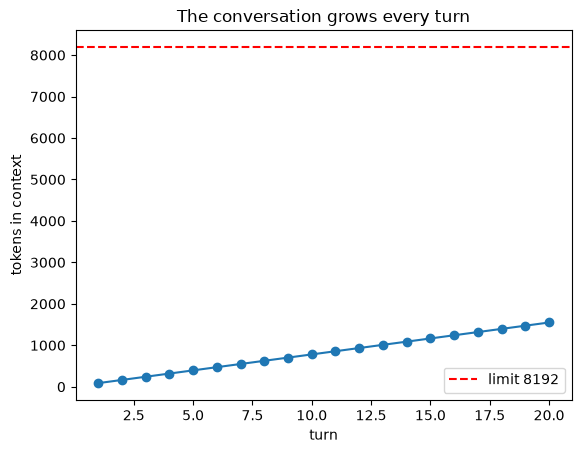

tokens at turn 20: 1550


In [8]:
import matplotlib.pyplot as plt
if TOKENIZER_OK:
    system = "You are a concise assistant for a retail bank."
    history = [{"role": "system", "content": system}]
    totals = []
    for turn in range(1, 21):
        history.append({"role": "user", "content": f"Turn {turn}: {TEXTS['english']}"})
        history.append({"role": "assistant", "content": "Certainly. " + "Here is a detailed answer about your loan. " * 6})
        totals.append(sum(count_tokens(m["content"]) for m in history))
    LIMIT = 8192   # a small window, for the picture; real models are far larger — but so are real conversations with documents
    plt.plot(range(1, 21), totals, marker="o"); plt.axhline(LIMIT, color="red", linestyle="--", label=f"limit {LIMIT}")
    plt.xlabel("turn"); plt.ylabel("tokens in context"); plt.title("The conversation grows every turn"); plt.legend(); plt.show()
    print("tokens at turn 20:", totals[-1])
else:
    print('skipped (no tokenizer: tiktoken could not download its dictionary file; connect to the internet once and re-run)')

### What you should see
A rising straight line of dots, and a dashed red line at 8,192 far above it. Then (real output; the tokenizer is deterministic):
```
tokens at turn 20: 1550
```
**How to read it — and a surprise.** The line **does not reach the limit** in 20 turns. Each turn adds a user message (about 20 tokens) and an answer (57 tokens): about **77 tokens per turn**, from 87 after turn 1. Predict, then calculate: when would it cross 8,192? (About (8,192 − 10) ÷ 77 ≈ 106 turns.)

So is the window not a problem? It is, for reasons this toy leaves out: real answers are longer, real users paste documents (one three-page statement can be a few thousand tokens in a single turn, so the line *jumps*), the wrapper is not counted, and agents and RAG add tool results and retrieved text (Sessions 30, 34, 38). And on the *cost* side, by turn 20 every message re-sends about 1,550 tokens of history.

If you see `NameError: name 'TEXTS' is not defined`, section 2 was not run in this kernel: run from the top.

### Check yourself
*Question 4 — At turn 21, what is in the window and what has to go? Who decides?*

(Answer it twice: for this simulation with `LIMIT = 8192`, and for a real chat where the customer pasted a long statement at turn 3.)

> **Common mistake:** thinking a bigger context window solves the problem. A bigger desk fills more slowly, but every token on it is paid for on every call, and models can make less use of material buried in a very long context. What to keep is your design decision (Sessions 19 and 38).

## 6. Embeddings — meaning as coordinates

### What and why
An **embedding model** does not answer. It turns text into a **vector** — a list of numbers (768 here) — such that similar meanings land close together. We embed ten words with a local model, squash 768 dimensions to 2 with PCA (plain NumPy), and draw them. If Ollama is not running, the notebook loads a cached copy made with the same model.

Where this comes back: **Module 4** (vector databases), **Module 5** (RAG), **Session 39** (agentic RAG).

This fixes the third problem in the A1 story: *"my EMI bounced"* and *"loan instalment payment failed"* share no words, but their vectors are close.

### The idea: a map of meaning
```
            ▲  direction 2                                 Think of a city map:
            │        hospital   doctor                     Hitech City and Gachibowli are close;
            │             prescription                     Charminar is further away.
            │                                              An embedding model draws such a map,
            │                         cricket              but of MEANING, and with 768 directions
            │   loan  EMI                                  instead of 2.
            │  interest  credit score    monsoon
            │       bank
            └──────────────────────────────────► direction 1      (an illustration, not a real run)
```
**Close points mean similar meaning.** We cannot draw 768 directions, so **PCA** flattens them to the two in which these ten words differ most, like a globe flattened into a paper map. Real search (Session 24) uses all 768.

**Predict first.** Look at the ten words: *loan, EMI, interest, credit score, bank, hospital, doctor, prescription, cricket, monsoon.* Which word will land closest to *loan*? Which word will sit alone?

### What the next cell does
1. **`load_points(WORDS)`** tries Ollama (`nomic-embed-text`, one request for ten words), then the file `module01/embeddings_10words.json`, then applies PCA. It returns `(points, source)`.
2. **`except RuntimeError as e:`** (added) catches the helper's error when neither source exists, and keeps its message. **`if pts is not None:`** runs the original drawing code only when we have points.
3. **`plt.scatter(pts[:, 0], pts[:, 1])`** draws the dots. `pts` is a NumPy *array* of shape 10 × 2; **`pts[:, 0]`** is "all rows, column 0".
4. **`for w, (x, y) in zip(WORDS, pts):`** — **`zip`** walks two lists side by side; `(x, y)` unpacks each point. **`plt.annotate`** writes each word next to its dot.

source: cache:embeddings_10words.json


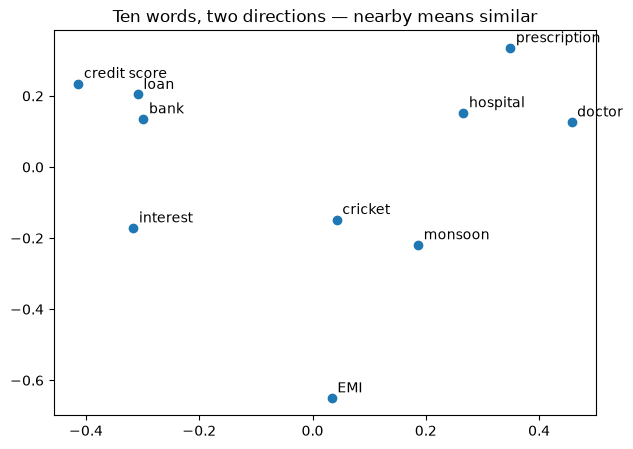

In [9]:
try:
    pts, source = load_points(WORDS)
except RuntimeError as e:          # no Ollama AND no cached file: skip, do not crash
    pts, source = None, f"skipped ({e})"
if pts is not None:
    print("source:", source)
    plt.figure(figsize=(7, 5))
    plt.scatter(pts[:, 0], pts[:, 1])
    for w, (x, y) in zip(WORDS, pts):
        plt.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points")
    plt.title("Ten words, two directions — nearby means similar"); plt.show()
else:
    print(source)

### What you should see
First a `source:` line, then the picture.

| If you see... | It means... |
|---|---|
| `source: ollama:nomic-embed-text` | your laptop computed the vectors just now |
| `source: cache:embeddings_10words.json` | Ollama was not available; the vectors come from the saved file, made with the same model |
| `skipped (No embedding source. ...)` | neither is available: start Ollama and `ollama pull nomic-embed-text` (about 270 MB), or `git pull` in case the cache file has been added; re-run |

**How to read the picture.** Look for neighbourhoods: money words together, medical words together. The picture may be mirrored or rotated compared with your neighbour's; only *distances* matter. A word in an unexpected place is interesting, not wrong: embeddings learn from how words appear together in text, not from logic. *Monsoon* may sit nearer the money words than you expect, because crop loans and monsoon rains appear together in a lot of Indian writing.

**One rule to carry forward:** vectors from different embedding models cannot be compared; each model draws its own map. Choose one embedding model, and if you change it, re-embed everything.

### Under the hood: rebuild `pca_2d` yourself
`load_points` uses `pca_2d`, a three-line PCA in plain NumPy. Here it is rebuilt and checked on made-up data (ten "words" of 768 random numbers), so no Ollama or file is needed.

**What the next cell does:**
1. **`np.random.default_rng(0)`** is a random generator with a fixed *seed*, so every laptop gets the same numbers. **`.normal(size=(10, 768))`** makes a 10 × 768 array.
2. **`my_pca_2d`**: (a) *centre* the data (subtract each column's average); (b) **`np.linalg.svd`** finds the directions of biggest spread, strongest first; (c) *project* every point onto the first two with **`@`** (matrix multiplication).
3. **`np.allclose`** checks equality up to tiny rounding differences; we assert your version matches the helper.
4. Prints how much of the total spread the two kept directions explain.

In [10]:
# Under the hood (offline, deterministic): PCA rebuilt in plain NumPy, checked against tokens_utils.pca_2d
import numpy as np

vecs = np.random.default_rng(0).normal(size=(10, 768))     # stand-in for 10 embeddings of 768 numbers

def my_pca_2d(x):
    xc = x - x.mean(axis=0)                                  # (a) centre: subtract each column's average
    _, s, vt = np.linalg.svd(xc, full_matrices=False)        # (b) directions of biggest spread, strongest first
    return xc @ vt[:2].T, s                                  # (c) project onto the first two directions

mine, s = my_pca_2d(vecs)
assert np.allclose(mine, pca_2d(vecs)), "different from the real helper"
kept = (s[:2] ** 2).sum() / (s ** 2).sum()                   # share of the total spread the 2-D picture keeps
print("shape in:", vecs.shape, "→ shape out:", mine.shape, "· same as the real helper")
print(f"the 2-D picture keeps {kept:.0%} of the spread of these random vectors")

shape in: (10, 768) → shape out: (10, 2) · same as the real helper
the 2-D picture keeps 25% of the spread of these random vectors


### What you should see
Real output (deterministic):
```
shape in: (10, 768) → shape out: (10, 2) · same as the real helper
the 2-D picture keeps 25% of the spread of these random vectors
```
Random vectors have no strong directions, so the flat picture keeps only a quarter of the spread. Real embeddings of related words often have stronger directions, so the picture shows more, but never everything. **PCA is for the picture, not for the search.**

### Check yourself
*Question 5 — Which words cluster? Which word sits alone, and why? What can an embedding model **not** do?*

> **Common mistake:** thinking an embedding model can answer. It returns numbers: it cannot answer, write or check facts, only place texts near or far. Turning nearness into an answer is a chat model's job, with retrieval (Module 5).

## 7. Reflection
Answer the five questions above here, one or two lines each.

1.The Telugu sentence uses 25 tokens, while the English sentence uses 16 tokens because the tokenizer splits Telugu words into more smaller pieces. A bank should measure token usage for each language to estimate costs and context limits accurately.

2.The Telugu sentence row shows this most clearly. The same sentence can produce different token counts depending on the tokenizer used by the model. Therefore, token counts are a property of the model’s tokenizer, not just the text itself.

3.I should ask the model to give concise, relevant answers and avoid unnecessary details. This reduces output tokens and helps lower the overall cost, especially when the application handles many requests.

4.In the simulation, the conversation history, system message, user messages, and assistant answers remain within the 8,192-token limit, so nothing needs to be removed at turn 21. In a real chat with a long statement, the application should decide what to keep, summarize, or remove to stay within the context limit.

5.Words with related meanings, such as loan, EMI, interest, bank, and credit score, may cluster together, while cricket or monsoon may be farther away. An embedding model converts text into numerical vectors but cannot independently generate answers or verify facts.

Then run the checkpoint from the terminal: `uv run pytest tests/test_s09.py`

(Add `-rs` to see why any test was skipped: `uv run pytest tests/test_s09.py -rs`. A skipped test is not a pass.)

**A good answer has three parts:** what *your* screen showed, what it means, and what you would do in a real system.

---
# Part C · Wrap-up

## C1. Summary
- A model never sees letters or words, but **tokens**: text becomes bytes, bytes become dictionary pieces, pieces become numbers.
- The **tokenizer belongs to the model**. The same sentence gives different counts on different models; Telugu, code and JSON cost more tokens than English prose for the same length.
- `tiktoken` counts *your text* before you send; the **`usage`** field reports *everything the model read*, including the chat-template wrapper. For budgets, trust `usage`.
- **Cost** = tokens in × input price + tokens out × output price. Output is priced higher, and the answer usually dominates the bill; the choice of model moves the bill most of all.
- The **context window** is a budget. The model remembers nothing: your code re-sends the whole history every turn, so the pile, and the cost per turn, grows. What to drop is your decision.
- An **embedding model** turns text into a vector, so similar meanings land close together. It never answers. PCA flattens the vectors for a picture only; vectors from different embedding models cannot be compared.

## C2. The words again

| Term | One-line meaning |
|---|---|
| Provider / model | Where the model runs (`BASE_URL`) / which brain answers (`MODEL`) |
| Token | A piece of text from the model's fixed dictionary; about ¾ of an English word |
| Tokenizer | The dictionary and rules that cut text into tokens; belongs to the model |
| Encoding (`o200k_harmony`), `tiktoken` | The name of one tokenizer dictionary; the library that counts with it |
| `usage` | `prompt_tokens`, `completion_tokens`, `total_tokens`: the truth after you send |
| Chat template (wrapper) | Extra tokens the provider adds around your messages; counted and billed |
| Input / output price | Separate prices per million tokens; output is higher |
| Context window | The most tokens a model can see at once; everything must fit |
| Next-token prediction | Score every possible next token, pick one, repeat |
| Attention | How the model weighs which earlier tokens matter for the next one |
| Embedding / vector | A list of numbers standing for meaning; close = similar |
| Embedding model | A model that returns vectors, never text |
| PCA | Flattens many dimensions to two, for pictures only |
| Pre-training / fine-tuning / preference tuning | Read the library / learn to follow instructions / learn which answers people prefer |
| Knowledge cutoff | The date the model stopped learning; later facts must come from the context |

## C3. Interview practice
Each answer: a definition, an example from this lab, one honest limit.

**1. What is a token, and why not just words?** A piece of text from the model's fixed dictionary (a word, part of a word, a space, digits, punctuation); sub-word pieces keep the dictionary manageable and still handle names, typos and any language. *Lab:* 16 tokens for 13 words; *rupees* = `' ru'` + `'pees'`. *Limit:* "¾ of a word" is an English average; Telugu, code and JSON differ, so count with the tokenizer.

**2. Why can the provider's count differ from yours?** The tokenizer belongs to the model, and the provider adds a chat template that is read and billed. *Lab:* Groq's `prompt_tokens` exceeded `tiktoken` by about the same amount in every row; Ollama's Llama differed again. *Limit:* the wrapper changes with provider and model version, so measure it, do not hard-code it.

**3. How would you estimate monthly cost?** Calls × (tokens in × input price + tokens out × output price) ÷ 1,000,000, with input including system prompt, history, documents and wrapper, output including hidden reasoning tokens, averages taken from `usage` in a pilot, plus a margin. *Lab:* output was about 97% of a call's cost; the flagship card cost about 80× the first. *Limit:* the lab's cards are indicative; prices change.

**4. What is a context window, and what happens when a chat is longer?** The most tokens one call can hold: system prompt, history, documents, tool results, answer. The model keeps no memory, so history is re-sent and grows; when it no longer fits, something is dropped or summarised, and if the application does not decide, the request fails or old content is cut. *Lab:* +77 tokens per turn, 1,550 at turn 20, under 8,192, until someone pastes a document. *Limit:* a bigger window costs more per call and long contexts are used less reliably.

**5. What is an embedding, and what is it for?** A vector representing meaning, so similar texts are close: the basis of semantic search, RAG, clustering, duplicate detection. *Lab:* 768 numbers per word from `nomic-embed-text`, flattened with PCA into neighbourhoods. *Limit:* it cannot answer or check facts, closeness reflects co-occurrence rather than logic, and vectors from different models cannot be mixed.

## C4. Troubleshooting

| Symptom | Cause | Fix |
|---|---|---|
| `tokenizer not available (ConnectionError)` / `ProxyError` naming `openaipublic.blob.core.windows.net` | `tiktoken` downloads its dictionary on first use and could not reach the internet | connect once (a phone hotspot works) and re-run; after that it works offline. An office proxy may block it |
| `ModuleNotFoundError: No module named 'tiktoken'` (or `numpy`, `matplotlib`) | `uv sync` not run after `git pull` | `uv sync`, then **Kernel → Restart** |
| Imports fail although `uv sync` worked | wrong kernel (for example Anaconda's) | select the project `.venv` kernel, or start with `uv run jupyter lab` |
| `skipped (no API key in .env)` | no `.env`, or the placeholder is still there | `copy .env.example .env`, paste your key, restart the kernel |
| `AuthenticationError` / 401 | wrong key, or quotes/spaces | fix the `API_KEY` line; restart |
| `RateLimitError` / 429 | free-tier burst limit | wait 30 seconds, re-run the cell |
| 404 model not found, name ends with `# pinned for the batch` | inline comment on the `MODEL` line of `.env` | `git pull`, then restart the kernel |
| `(no ollama)` in section 3 | Ollama not running, or `llama3.2:3b` not pulled | optional: start Ollama, `ollama pull llama3.2:3b` |
| `skipped (No embedding source ...)` | no Ollama and no `embeddings_10words.json` | `ollama pull nomic-embed-text` with Ollama running, or `git pull` and ask the instructor about the cache file |
| No plot appears | the cell ran outside a notebook | run it in Jupyter or a VS Code notebook |
| `test_estimate_matches_model_usage` fails: "estimate X vs usage Y" | the wrapper, or a `MODEL` with another tokenizer, makes the gap bigger than the test allows | note both numbers for Question 2 and tell the instructor |
| A test shows `s` (skipped) | the key, or Ollama / the cache file, is missing | run with `-rs` to read why; a skip is not a pass |

## C5. What comes next
**Session 10 — The model landscape.** You choose a model for the loan assistant under three constraints: cost, data residency and latency. Today's numbers (tokens per request, prices, context length) are the inputs.

**Keep from today:**
- Your measured **wrapper size** from section 3, and the cost of 1,000 calls on each card from section 4.
- The sentence: *"Training is who the model is; the context is what it knows right now."*
- Before Session 10: read `module01/reading_landscape.md`, and bring one constraint a real bank would have when choosing a model (cost, residency or latency).